# 🏁 Análise Final — Comparação dos Melhores Modelos

Último passo da pipeline. Corre **depois** das 4 tasks de experimentação (XGBoost F2, XGBoost F1, CatBoost, LightGBM).

**O que faz**
1. Lê os 4 experimentos MLflow e escolhe a melhor run de cada um (maior `f2_cv_mean` — que no experimento F1 é, na verdade, F1).
2. Reconstrói o **mesmo split 60/20/20** (seed 42) e reavalia os 4 modelos **na mesma métrica e no mesmo teste** (F2 como métrica oficial).
3. Calibra o threshold no **validação** (nunca no teste), mede overfitting (treino vs val vs teste), ROC-AUC, PR-AUC e matriz de confusão.
4. Compara com bootstrap pareado (o teste é pequeno: diferenças de ~0.005 em F2 costumam ser ruído).
5. Mostra parâmetros, features e importâncias por modelo, declara o vencedor e regista tudo no MLflow.

**Configuração da task no Job:** *Depends on* = as 4 tasks de experimentação · *Run if* = `All done` (corre mesmo que uma tenha falhado; o notebook ignora com aviso um experimento sem runs).

In [0]:
# Alinha as bibliotecas com as usadas no TREINO: o erro "Can't get attribute '_RemainderColsList'" é versão diferente de scikit-learn
# entre quem gravou o modelo (tasks de experimentação) e quem o lê (este notebook). Lê as versões gravadas no MLflow e instala-as.
import re, subprocess, sys
import mlflow, mlflow.pyfunc

_BASE = "/Users/brenofontesx@gmail.com/Adult_Income"
_PATHS = [f"{_BASE}/adult_income_exp", f"{_BASE}/adult_income_exp_f1", f"{_BASE}/adult_income_exp_catboost", f"{_BASE}/adult_income_exp_f1_lgbm"]
_WATCH = {"scikit-learn", "xgboost", "lightgbm", "catboost", "cloudpickle"}

_pins = {}
for _p in _PATHS:
    _exp = mlflow.get_experiment_by_name(_p)
    if _exp is None:
        continue
    _runs = mlflow.search_runs(experiment_ids=[_exp.experiment_id], filter_string="metrics.f2_cv_mean > 0",
                               order_by=["metrics.f2_cv_mean DESC"], max_results=1)
    if _runs.empty:
        continue
    _req = mlflow.pyfunc.get_model_dependencies(f"runs:/{_runs.iloc[0]['run_id']}/model")
    for _line in open(_req):
        _m = re.match(r"^\s*([A-Za-z0-9_.\-]+)\s*==\s*([^\s;#]+)", _line)
        if _m and _m.group(1).lower().replace("_", "-") in _WATCH:
            _pins.setdefault(_m.group(1).lower().replace("_", "-"), set()).add(_m.group(2))

_to_install = []
for _pkg, _vs in _pins.items():
    if len(_vs) == 1:
        _to_install.append(f"{_pkg}=={next(iter(_vs))}")
    else:
        print(f"⚠️ {_pkg}: versões diferentes entre experimentos {sorted(_vs)} — sem pin (alinha os ambientes de treino)")
for _pkg in ("catboost", "lightgbm"):
    if _pkg not in _pins:
        _to_install.append(_pkg)

print("A instalar:", _to_install)
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_to_install])

2026/10/09 22:23:42 INFO mlflow.pyfunc: To install the dependencies that were used to train the model, run the following command: '%pip install -r /local_disk0/user_tmp_data/spark-0606239d-653b-45a0-9924-7a/tmp_zdzi8sy/model/requirements.txt'.


2026/10/09 22:23:46 INFO mlflow.pyfunc: To install the dependencies that were used to train the model, run the following command: '%pip install -r /local_disk0/user_tmp_data/spark-0606239d-653b-45a0-9924-7a/tmphquw16o1/model/requirements.txt'.


2026/10/09 22:23:55 INFO mlflow.pyfunc: To install the dependencies that were used to train the model, run the following command: '%pip install -r /local_disk0/user_tmp_data/spark-0606239d-653b-45a0-9924-7a/tmpqhieounn/model/requirements.txt'.


2026/10/09 22:24:07 INFO mlflow.pyfunc: To install the dependencies that were used to train the model, run the following command: '%pip install -r /local_disk0/user_tmp_data/spark-0606239d-653b-45a0-9924-7a/tmp_xr04m_y/model/requirements.txt'.


A instalar: ['cloudpickle==3.0.0', 'scikit-learn==1.6.1', 'xgboost==3.4.1', 'catboost==1.2.10', 'lightgbm==4.7.0']


0

In [0]:
dbutils.library.restartPython()

In [0]:
# ============================== CONFIG ==============================
import json, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import mlflow.catboost
from sklearn.model_selection import train_test_split
from sklearn.metrics import (fbeta_score, f1_score, precision_score, recall_score, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=UserWarning)

BASE = "/Users/brenofontesx@gmail.com/Adult_Income"
GOLD_TABLE = "adult_income.adult_income_gold.ad_inc_gold"
COMPARISON_EXPERIMENT = f"{BASE}/adult_income_model_comparison"
SEED = 42

# ATENÇÃO aos nomes: pelo código dos notebooks, o experimento "adult_income_exp_f1_lgbm" usa beta=2 (F2),
# e o notebook "F2-Score ... R05_01" grava em "adult_income_exp_f1" com beta=1 (F1) (nomes de ficheiro/experimento trocados).
EXPERIMENTS = {
    "XGBoost (F2)":  dict(path=f"{BASE}/adult_income_exp",          flavor="sklearn",  objective="F2"),
    "XGBoost (F1)":  dict(path=f"{BASE}/adult_income_exp_f1",       flavor="sklearn",  objective="F1"),
    "CatBoost (F2)": dict(path=f"{BASE}/adult_income_exp_catboost", flavor="catboost", objective="F2"),
    "LightGBM (F2)": dict(path=f"{BASE}/adult_income_exp_f1_lgbm",  flavor="sklearn",  objective="F2"),
}

THR_GRID = np.arange(0.05, 0.951, 0.01)     # threshold tuning (no VALIDAÇÃO)
OVERFIT_OK, OVERFIT_ACTION = 0.05, 0.10     # gap F2 treino-teste em pontos absolutos: <5% ok | 5-10% investigar | >10% ação
N_BOOT = 1000                               # reamostragens bootstrap no teste
P_ROBUST = 0.95                             # P(vencedor > 2º) mínima para falar em vantagem robusta

def show(df):
    try: display(df)
    except NameError: print(df.to_string())

In [0]:
# ============================ DADOS (mesmo split dos notebooks de experimentação) ============================
df_frame = spark.table(GOLD_TABLE).toPandas()
y = df_frame["class"].apply(lambda v: 1 if v == ">50K" else 0)

df_train, df_temp, y_train_t, y_temp = train_test_split(df_frame, y, test_size=0.4, random_state=SEED, stratify=y)
df_val, df_test, _, _ = train_test_split(df_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp)

to_y = lambda d: d["class"].apply(lambda v: 1 if v == ">50K" else 0)
y_train, y_val, y_test = to_y(df_train), to_y(df_val), to_y(df_test)
Y = {"train": y_train.values, "val": y_val.values, "test": y_test.values}
DF = {"train": df_train, "val": df_val, "test": df_test}

categorical_features = ["marital-status", "native-country", "occupation", "race", "relationship", "workclass"]

def prepare_catboost_input(df, features, categorical_cols=categorical_features):
    """Idêntica à do notebook CatBoost: categóricas -> str."""
    X = df[features].copy()
    cat_in = [c for c in categorical_cols if c in features]
    for col in cat_in:
        X[col] = X[col].astype(str).fillna("missing")
    return X, cat_in

for s in ("train", "val", "test"):
    print(f"{s:>5}: {len(DF[s]):>6,} linhas | >50K = {Y[s].mean()*100:.1f}%")

{"ts": "2026-10-09 22:24:31.184", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvMTU0MTM4NTk2NTA3MjE1MBABIAEyJDAxYTEyMmMzLTU3Y2QtNzA1MC04OTEzLWFkOTE4MTQzZDM1NjokOTIwYTE1MmItZThlZC0zMTZjLWEwYmUtYjczNTk2OTY1NzMzSgwIzdKl1gYQwJbM8AJQAVgBYAFoy+Wom/PEow2IAQA=.", "context": {}}
{"ts": "2026-10-09 22:24:31.184", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvMTU0MTM4NTk2NTA3MjE1MBABIAEyJDAxYTEyMmMzLTU3Y2QtNzA1MC04OTEzLWFkOTE4MTQzZDM1NjokOTIwYTE1MmItZThlZC0zMTZjLWEwYmUtYjczNTk2OTY1NzMzSgwIzdKl1gYQwJbM8AJQAVgBYAFoy+Wom/PEow2IAQA=.", "context": {}}
{"ts": "2026-10-09 22:24:31.184", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvMTU0MTM4NTk2NTA3MjE1MBABIAEyJDAxYTEyMmMzLTU3Y2QtNzA1MC04OTEzLWFkOTE4MTQzZDM1NjokOTIwYTE1MmItZThlZC0zMTZjLWEwYmUtYjczNTk2

train: 29,305 linhas | >50K = 23.9%
  val:  9,768 linhas | >50K = 23.9%
 test:  9,769 linhas | >50K = 23.9%


## 1 · Melhor run de cada experimento
Seleção por `f2_cv_mean` **dentro** de cada experimento (no XGBoost F1 essa coluna é F1). A comparação entre modelos só acontece depois, no teste e na mesma métrica.

In [0]:
best, rows = {}, []
for name, cfg in EXPERIMENTS.items():
    exp = mlflow.get_experiment_by_name(cfg["path"])
    if exp is None:
        print(f"⚠️ {name}: experimento não encontrado ({cfg['path']}) — IGNORADO"); continue
    runs = mlflow.search_runs(experiment_ids=[exp.experiment_id])
    if "metrics.f2_cv_mean" not in runs.columns or "params.features" not in runs.columns:
        print(f"⚠️ {name}: sem runs com métricas — IGNORADO"); continue
    ok = runs[runs["metrics.f2_cv_mean"].notna() & runs["params.features"].notna()]
    if "status" in ok.columns:
        ok = ok[ok["status"] == "FINISHED"]
    ok = ok.sort_values("metrics.f2_cv_mean", ascending=False)
    if ok.empty:
        print(f"⚠️ {name}: nenhuma run válida — IGNORADO"); continue
    top = ok.iloc[0]
    feats = [f.strip() for f in top["params.features"].split(",")]
    best[name] = dict(run_id=top["run_id"], features=feats, flavor=cfg["flavor"], objective=cfg["objective"],
                      cv_mean=top["metrics.f2_cv_mean"], cv_std=top.get("metrics.f2_cv_std", np.nan),
                      cv_recall=top.get("metrics.recall_cv_mean", np.nan), cv_precision=top.get("metrics.precision_cv_mean", np.nan),
                      n_runs=len(ok), cv_median=ok["metrics.f2_cv_mean"].median())
    rows.append(dict(Modelo=name, Objetivo=cfg["objective"], Runs=len(ok), CV_melhor=round(top["metrics.f2_cv_mean"], 4),
                     CV_std=round(top.get("metrics.f2_cv_std", np.nan), 4), CV_mediana_runs=round(ok["metrics.f2_cv_mean"].median(), 4),
                     N_features=len(feats), run_id=top["run_id"]))

if len(best) < 2:
    raise RuntimeError(f"Só {len(best)} experimento(s) com runs válidas — nada para comparar.")
show(pd.DataFrame(rows))

Modelo,Objetivo,Runs,CV_melhor,CV_std,CV_mediana_runs,N_features,run_id
XGBoost (F2),F2,27235,0.7832,0.0056,0.7515,11,6bc415dba9cd4f9eb39afe1ae8d65fc7
XGBoost (F1),F1,6000,0.69,0.0043,0.6598,11,98e3f0dd1490404398cb55e860b4395e
CatBoost (F2),F2,2040,0.7832,0.0071,0.7663,9,aefb2208bdff4bc88b818a35104b9073
LightGBM (F2),F2,4500,0.7828,0.0067,0.7581,11,a8a6bfe2cc724340952325f86418b8cb


In [0]:
# ============ Carregar modelos do MLflow e gerar probabilidades (treino/val/teste) ============
def load_model(flavor, run_id):
    uri = f"runs:/{run_id}/model"
    return mlflow.catboost.load_model(uri) if flavor == "catboost" else mlflow.sklearn.load_model(uri)

def predict_proba(model, flavor, df, features):
    if flavor == "catboost":
        X, _ = prepare_catboost_input(df, features)
    else:
        X = df[features]
    return model.predict_proba(X)[:, 1]

models, proba = {}, {}
for name, b in best.items():
    models[name] = load_model(b["flavor"], b["run_id"])
    proba[name] = {s: predict_proba(models[name], b["flavor"], DF[s], b["features"]) for s in DF}
print("✅ Modelos carregados:", list(models))

✅ Modelos carregados: ['XGBoost (F2)', 'XGBoost (F1)', 'CatBoost (F2)', 'LightGBM (F2)']


## 2 · Métricas comparáveis (mesmo teste, F2 como métrica oficial)
Threshold afinado no **validação** (maximiza F2). Teste é usado só para reportar.

In [0]:
def fb(y_, p_, thr, beta): return fbeta_score(y_, (p_ >= thr).astype(int), beta=beta, zero_division=0)
def tune_threshold(y_, p_):
    sc = [fb(y_, p_, t, 2) for t in THR_GRID]
    return float(THR_GRID[int(np.argmax(sc))]), sc
def status(gap): return "OK" if gap <= OVERFIT_OK else ("INVESTIGAR" if gap <= OVERFIT_ACTION else "AÇÃO")

thr, val_curve, rows = {}, {}, []
for name, b in best.items():
    p = proba[name]
    thr[name], val_curve[name] = tune_threshold(Y["val"], p["val"])
    thr[name] = round(thr[name], 2)
    t = thr[name]
    pt = (p["test"] >= t).astype(int)
    f2_tr, f2_va, f2_te = (fb(Y[s], p[s], t, 2) for s in ("train", "val", "test"))
    own = fb(Y["test"], p["test"], 0.5, 1 if b["objective"] == "F1" else 2)   # métrica do próprio objetivo @0.5 (mesma regra do CV)
    gap = f2_tr - f2_te
    rows.append({
        "Modelo": name, "Threshold": t,
        "F2_teste": f2_te, "Recall": recall_score(Y["test"], pt), "Precision": precision_score(Y["test"], pt, zero_division=0),
        "F1_teste": f1_score(Y["test"], pt), "ROC_AUC": roc_auc_score(Y["test"], p["test"]), "PR_AUC": average_precision_score(Y["test"], p["test"]),
        "F2_teste@0.5": fb(Y["test"], p["test"], 0.5, 2),
        "F2_treino": f2_tr, "F2_val": f2_va, "Gap_treino-teste": gap, "Gap_val-teste": f2_va - f2_te, "Overfit": status(gap),
        "CV_vs_teste(obj@0.5)": b["cv_mean"] - own,
    })
comp = pd.DataFrame(rows).set_index("Modelo").sort_values("F2_teste", ascending=False)
show(comp.round(4))

Threshold,F2_teste,Recall,Precision,F1_teste,ROC_AUC,PR_AUC,F2_teste@0.5,F2_treino,F2_val,Gap_treino-teste,Gap_val-teste,Overfit,CV_vs_teste(obj@0.5)
0.39,0.7916,0.905,0.5272,0.6662,0.9124,0.7798,0.7856,0.8126,0.797,0.0211,0.0055,OK,-0.0044
0.37,0.7902,0.9281,0.4955,0.6461,0.9095,0.7696,0.7834,0.8005,0.793,0.0103,0.0028,OK,-6.0E-4
0.36,0.7884,0.9316,0.4883,0.6408,0.9088,0.7677,0.7834,0.7987,0.7938,0.0103,0.0053,OK,-2.0E-4
0.35,0.7863,0.935,0.4807,0.6349,0.9074,0.7655,0.7847,0.7999,0.791,0.0136,0.0046,OK,-0.0015


## 3 · Quem é o melhor? (bootstrap pareado no teste)
Vencedor = maior F2 de teste entre os modelos **sem** overfitting de nível "AÇÃO". Depois mede-se se a vantagem sobre o 2º é robusta ou empate técnico.

In [0]:
rng = np.random.default_rng(SEED)
n_te = len(Y["test"])
idx = rng.integers(0, n_te, size=(N_BOOT, n_te))
yb = Y["test"].astype(bool)[idx]

def boot_f2(name):
    pb = (proba[name]["test"] >= thr[name])[idx]
    tp = (yb & pb).sum(1); fp = (~yb & pb).sum(1); fn = (yb & ~pb).sum(1)
    return 5 * tp / np.maximum(5 * tp + 4 * fn + fp, 1)

boot = {n: boot_f2(n) for n in best}
ci = {n: (np.percentile(boot[n], 2.5), np.percentile(boot[n], 97.5)) for n in best}

eligible = comp[comp["Overfit"] != "AÇÃO"]
if eligible.empty:
    print("⚠️ Todos os modelos com overfitting > limite de ação — a ranquear mesmo assim por F2 de teste.")
    eligible = comp
ranking = list(eligible.index)
winner = ranking[0]
runner = ranking[1] if len(ranking) > 1 else None

comp["IC95_F2_inf"] = [ci[n][0] for n in comp.index]
comp["IC95_F2_sup"] = [ci[n][1] for n in comp.index]
comp["P(vence_vencedor)"] = [np.nan if n == winner else np.mean(boot[winner] > boot[n]) + 0.5 * np.mean(boot[winner] == boot[n]) for n in comp.index]
show(comp[["F2_teste", "IC95_F2_inf", "IC95_F2_sup", "P(vence_vencedor)", "Overfit"]].round(4))

p_win = comp.loc[runner, "P(vence_vencedor)"] if runner else 1.0
robust = bool(p_win >= P_ROBUST)
print(f"🏆 Melhor F2: {winner} | 2º: {runner} | P(melhor > 2º) = {p_win:.3f} → {'vantagem robusta' if robust else 'EMPATE TÉCNICO'}")

# Desempate: entre os modelos estatisticamente indistinguíveis do melhor, recomenda o de menor overfitting (gap treino-teste)
tied = [winner] + [n for n in comp.index if n != winner and n in eligible.index and comp.loc[n, "P(vence_vencedor)"] < P_ROBUST]
final = min(tied, key=lambda n: (max(comp.loc[n, "Gap_treino-teste"], 0), -comp.loc[n, "F2_teste"]))
print(f"✅ Modelo recomendado: {final}" + (f"  (empatados com o melhor: {tied})" if len(tied) > 1 else ""))

F2_teste,IC95_F2_inf,IC95_F2_sup,P(vence_vencedor),Overfit
0.7916,0.7805,0.8026,null,OK
0.7902,0.7793,0.8007,0.672,OK
0.7884,0.778,0.7986,0.835,OK
0.7863,0.7756,0.7968,0.946,OK


🏆 Melhor F2: XGBoost (F1) | 2º: LightGBM (F2) | P(melhor > 2º) = 0.672 → EMPATE TÉCNICO
✅ Modelo recomendado: LightGBM (F2)  (empatados com o melhor: ['XGBoost (F1)', 'LightGBM (F2)', 'CatBoost (F2)', 'XGBoost (F2)'])


## 4 · Curvas ROC, PR, threshold e matrizes de confusão (teste)

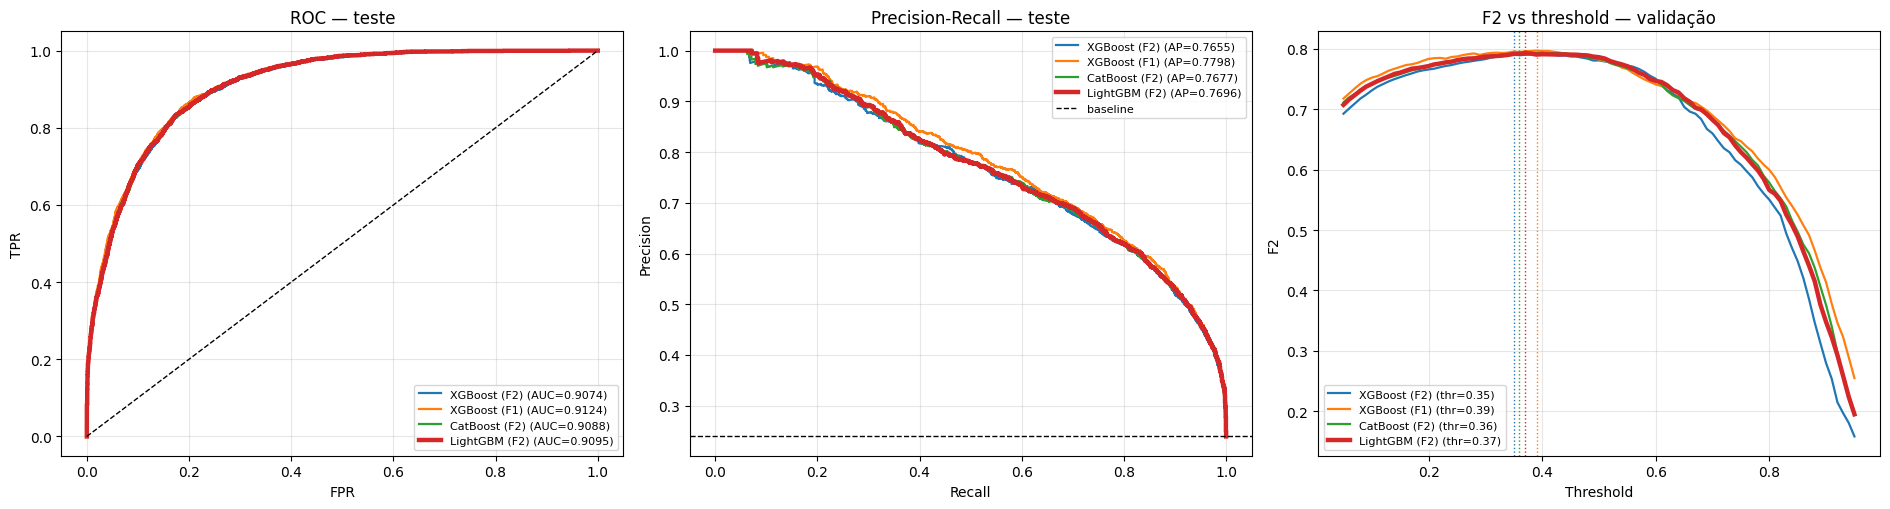

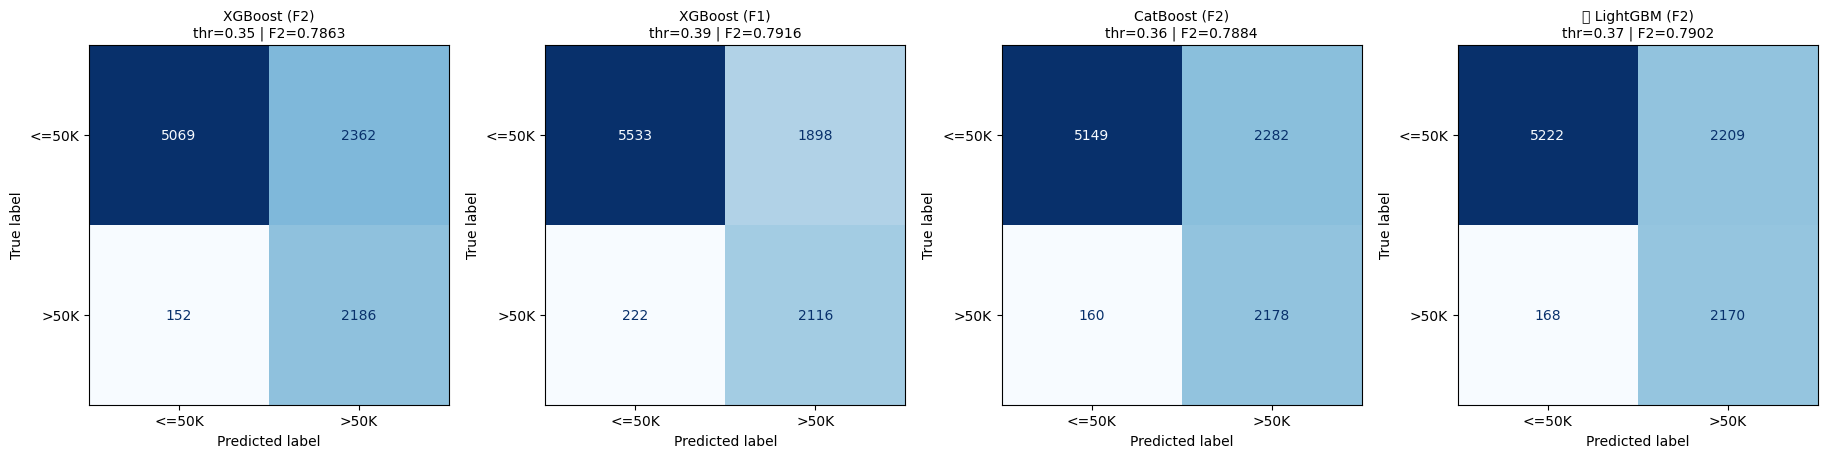

In [0]:
FIGS = []
colors = dict(zip(best, plt.cm.tab10.colors))
lw = lambda n: 3.2 if n == final else 1.6

fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
for n in best:
    fpr, tpr, _ = roc_curve(Y["test"], proba[n]["test"])
    ax[0].plot(fpr, tpr, color=colors[n], lw=lw(n), label=f"{n} (AUC={comp.loc[n,'ROC_AUC']:.4f})")
    pr, rc, _ = precision_recall_curve(Y["test"], proba[n]["test"])
    ax[1].plot(rc, pr, color=colors[n], lw=lw(n), label=f"{n} (AP={comp.loc[n,'PR_AUC']:.4f})")
    ax[2].plot(THR_GRID, val_curve[n], color=colors[n], lw=lw(n), label=f"{n} (thr={thr[n]:.2f})")
    ax[2].axvline(thr[n], color=colors[n], ls=":", lw=1)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set(title="ROC — teste", xlabel="FPR", ylabel="TPR")
ax[1].axhline(Y["test"].mean(), color="k", ls="--", lw=1, label="baseline"); ax[1].set(title="Precision-Recall — teste", xlabel="Recall", ylabel="Precision")
ax[2].set(title="F2 vs threshold — validação", xlabel="Threshold", ylabel="F2")
for a in ax: a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); FIGS.append((fig, "roc_pr_threshold.png")); plt.show()

fig, axes = plt.subplots(1, len(best), figsize=(4.6 * len(best), 4.4))
for a, n in zip(np.atleast_1d(axes), best):
    cm = confusion_matrix(Y["test"], (proba[n]["test"] >= thr[n]).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["<=50K", ">50K"]).plot(ax=a, cmap="Blues", colorbar=False, values_format="d")
    a.set_title(f"{'🏆 ' if n == final else ''}{n}\nthr={thr[n]:.2f} | F2={comp.loc[n,'F2_teste']:.4f}", fontsize=10)
plt.tight_layout(); FIGS.append((fig, "confusion_matrices.png")); plt.show()

## 5 · Overfitting (treino vs validação vs teste)
Gap = F2 treino − F2 teste (pontos absolutos, mesmo threshold). Regra do projeto: <5% ok · 5–10% investigar · >10% ação.

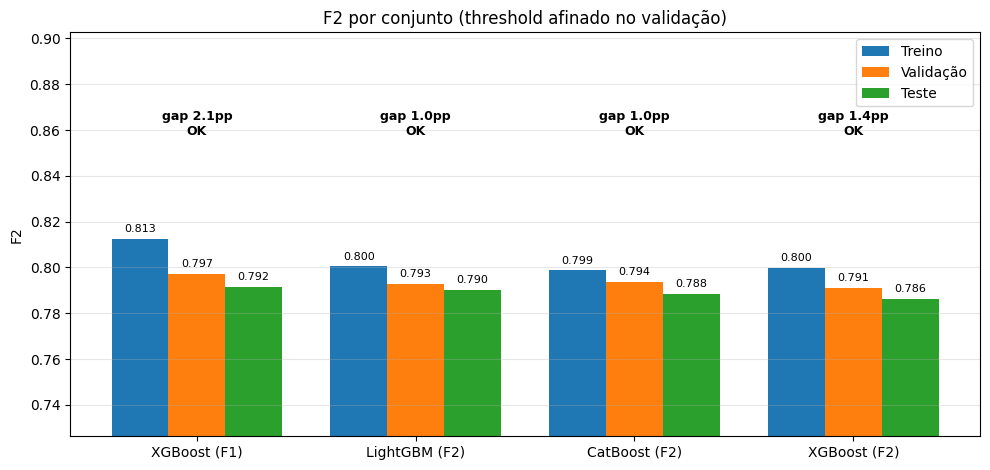

In [0]:
fig, ax = plt.subplots(figsize=(10, 4.8))
w, x = 0.26, np.arange(len(comp))
for i, (col, lab) in enumerate([("F2_treino", "Treino"), ("F2_val", "Validação"), ("F2_teste", "Teste")]):
    bars = ax.bar(x + (i - 1) * w, comp[col], w, label=lab)
    for r in bars: ax.text(r.get_x() + r.get_width() / 2, r.get_height() + .003, f"{r.get_height():.3f}", ha="center", fontsize=8)
top_y = comp[["F2_treino", "F2_val", "F2_teste"]].values.max()
for xi, (n, r) in zip(x, comp.iterrows()):
    ax.text(xi, top_y + .045, f"gap {r['Gap_treino-teste']*100:.1f}pp\n{r['Overfit']}", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(comp.index); ax.set_ylim(comp[["F2_treino", "F2_val", "F2_teste"]].values.min() - .06, top_y + .09)
ax.set(title="F2 por conjunto (threshold afinado no validação)", ylabel="F2"); ax.legend(); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); FIGS.append((fig, "overfitting.png")); plt.show()

## 6 · Melhores parâmetros, features e importâncias por modelo

XGBoost (F2) — run 6bc415db — 11 features
Features: age, education-num, hours-per-week, is_married, occupation, relationship, is_capital_gain, native-country, capital-loss, is_wife, sex_ord
Parâmetros: {'colsample_bytree': 0.9, 'eval_metric': 'logloss', 'gamma': 0.1, 'learning_rate': 0.01, 'max_depth': 5, 'min_child_weight': 5, 'missing': nan, 'n_estimators': 500, 'random_state': 42, 'reg_alpha': 0, 'reg_lambda': 1.0, 'scale_pos_weight': np.float64(3.1792641186537365), 'subsample': 1.0}
Top-5 importância (%): {'is_married': 47.5, 'occupation': 18.0, 'relationship': 14.1, 'education-num': 7.0, 'is_capital_gain': 3.6}
XGBoost (F1) — run 98e3f0dd — 11 features
Features: age, education-num, hours-per-week, occupation, relationship, is_capital_gain, native-country, workclass, capital-loss, sex_ord, is_married_notmarried_divorced
Parâmetros: {'colsample_bytree': 1.0, 'eval_metric': 'logloss', 'gamma': 0, 'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 1, 'missing': nan, 'n_estimato

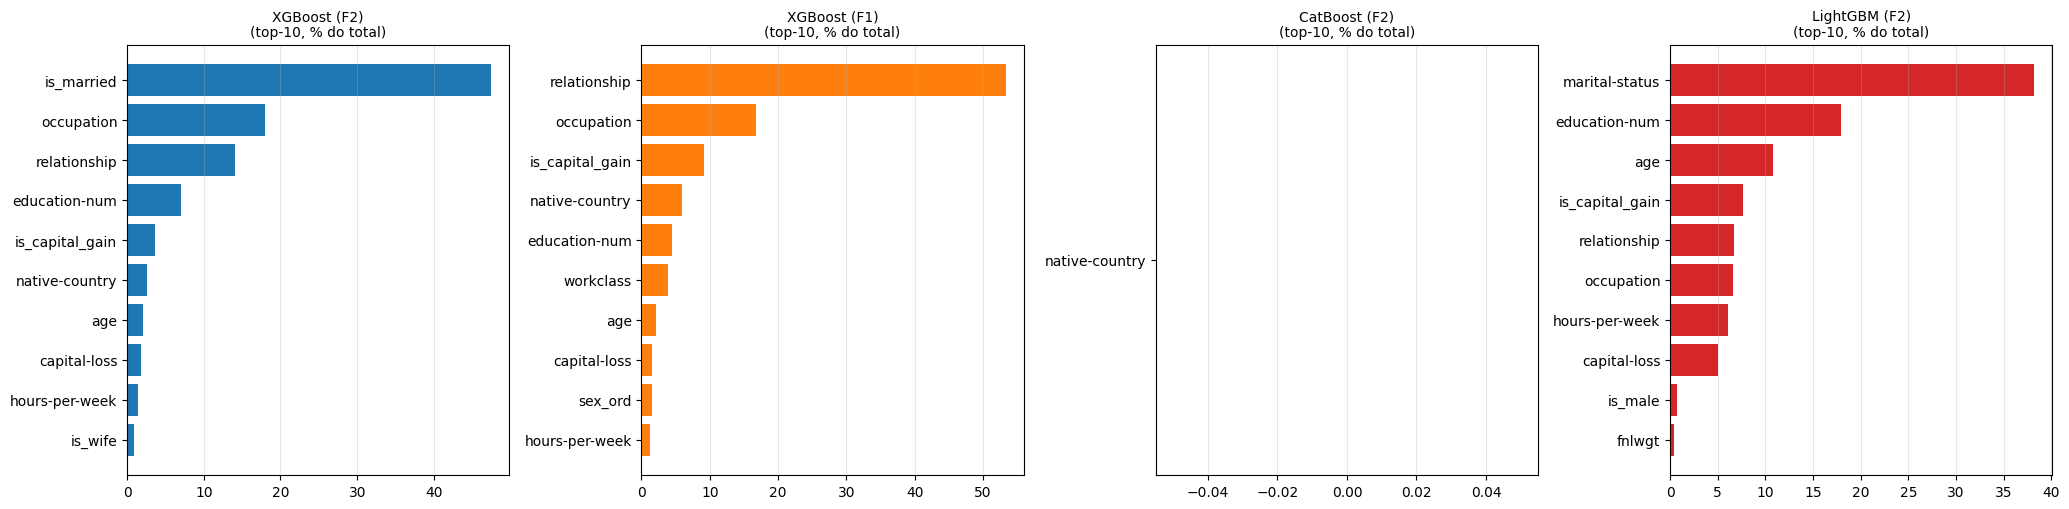

/home/spark-0606239d-653b-45a0-9924-7a/.ipykernel/67/command-5945225643140039-3209904674:44: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  imp_table = pd.concat(imps, axis=1).fillna(0).round(1)


XGBoost (F2),XGBoost (F1),CatBoost (F2),LightGBM (F2),n_modelos_top5
14.1,53.3,0,6.7,4
7.0,4.4,0,17.9,4
3.6,9.1,0,7.6,4
18.0,16.8,0,6.5,3
47.5,0.0,0,0.0,2
2.6,5.9,0,0.0,1
2.1,2.1,0,10.8,1
0.0,0.0,0,38.2,1
0.0,0.2,0,0.0,0
0.0,0.0,0,0.4,0


In [0]:
def non_default_params(model, flavor):
    if flavor == "catboost":
        keys = ["iterations", "depth", "learning_rate", "l2_leaf_reg", "bagging_temperature", "random_strength",
                "min_data_in_leaf", "rsm", "border_count", "one_hot_max_size", "max_ctr_complexity", "boosting_type"]
        ap = model.get_all_params()
        return {k: ap[k] for k in keys if k in ap}
    clf = model.named_steps["classifier"]
    defaults = type(clf)().get_params()
    return {k: v for k, v in clf.get_params().items() if k in defaults and v != defaults[k] and v is not None}

def importance(model, flavor):
    if flavor == "catboost":
        imp = pd.Series(model.feature_importances_, index=model.feature_names_)
    else:
        pre, clf = model.named_steps["preprocessor"], model.named_steps["classifier"]
        owners = []
        for tname, trans, cols in pre.transformers_:
            if tname == "remainder": continue
            if tname == "cat":
                for col, cats in zip(cols, trans.named_steps["ohe"].categories_): owners += [col] * len(cats)
            else:
                owners += list(cols)
        vals = np.asarray(clf.feature_importances_)
        if len(owners) != len(vals):
            raise ValueError(f"Importâncias ({len(vals)}) != colunas transformadas ({len(owners)})")
        imp = pd.Series(vals, index=owners).groupby(level=0).sum()   # re-agrega OHE pela coluna original
    return (imp / imp.sum() * 100).sort_values(ascending=False)

imps = {}
for n, b in best.items():
    imps[n] = importance(models[n], b["flavor"])
    print("=" * 90)
    print(f"{'🏆 ' if n == final else ''}{n} — run {b['run_id'][:8]} — {len(b['features'])} features")
    print("Features:", ", ".join(b["features"]))
    print("Parâmetros:", non_default_params(models[n], b["flavor"]))
    print("Top-5 importância (%):", {k: round(v, 1) for k, v in imps[n].head(5).items()})

fig, axes = plt.subplots(1, len(best), figsize=(5.2 * len(best), 5.2))
for a, n in zip(np.atleast_1d(axes), best):
    top = imps[n].head(10)[::-1]
    a.barh(top.index, top.values, color=colors[n]); a.set_title(f"{n}\n(top-10, % do total)", fontsize=10); a.grid(axis="x", alpha=.3)
plt.tight_layout(); FIGS.append((fig, "feature_importance.png")); plt.show()

imp_table = pd.concat(imps, axis=1).fillna(0).round(1)
imp_table["n_modelos_top5"] = sum((imp_table[n].rank(ascending=False, method="first") <= 5).astype(int) for n in best)
show(imp_table.sort_values("n_modelos_top5", ascending=False).head(15))

## 7 · Conclusão + registo no MLflow

In [0]:
w = comp.loc[final]
lines = [
    f"🏆 MELHOR MODELO: {final}" + ("" if final == winner else f"  (F2 absoluto mais alto: {winner}, mas estatisticamente empatado; desempate por menor overfitting)"),
    f"   F2 teste = {w['F2_teste']:.4f} (IC95% {w['IC95_F2_inf']:.4f}–{w['IC95_F2_sup']:.4f}) | Recall = {w['Recall']:.4f} | Precision = {w['Precision']:.4f} | threshold = {w['Threshold']:.2f}",
    f"   ROC-AUC = {w['ROC_AUC']:.4f} | PR-AUC = {w['PR_AUC']:.4f}",
    f"   Overfitting: gap treino-teste = {w['Gap_treino-teste']*100:.1f}pp → {w['Overfit']}",
]
if runner:
    d = comp.loc[winner, "F2_teste"] - comp.loc[runner, "F2_teste"]
    lines.append(f"   Melhor F2 ({winner}) vs 2º ({runner}): ΔF2 = {d:+.4f}, P(vence) = {p_win:.2f} → " +
                 ("vantagem robusta." if robust else f"EMPATE TÉCNICO entre {tied}: diferença dentro do ruído do teste."))
lines.append(f"   Top features (importância): {', '.join(f'{k} ({v:.0f}%)' for k, v in imps[final].head(5).items())}")
excluded = [n for n in comp.index if comp.loc[n, "Overfit"] == "AÇÃO"]
if excluded: lines.append(f"   ⚠️ Excluídos por overfitting > {OVERFIT_ACTION*100:.0f}pp: {excluded}")
if "XGBoost (F1)" in comp.index:
    lines.append(f"   ℹ️ XGBoost (F1) foi otimizado para F1, não F2; aqui é avaliado em F2 (F1 teste = {comp.loc['XGBoost (F1)','F1_teste']:.4f}).")
conclusion = "\n".join(lines)
print(conclusion)

mlflow.set_experiment(COMPARISON_EXPERIMENT)
with mlflow.start_run(run_name="model_comparison"):
    mlflow.set_tag("winner", final)
    mlflow.log_param("winner_source_run_id", best[final]["run_id"])
    mlflow.log_param("winner_features", ", ".join(best[final]["features"]))
    mlflow.log_param("tied_models", ", ".join(tied))
    mlflow.log_param("robust_vs_runner_up", robust)
    for n in comp.index:
        k = re.sub(r"\W+", "_", n).strip("_")
        for col in ["F2_teste", "Recall", "Precision", "ROC_AUC", "PR_AUC", "F2_treino", "F2_val", "Gap_treino-teste", "Threshold"]:
            mlflow.log_metric(f"{k}_{col.replace('-', '_')}", float(comp.loc[n, col]))
    mlflow.log_text(comp.round(5).to_csv(), "comparison.csv")
    mlflow.log_text(imp_table.to_csv(), "feature_importance.csv")
    mlflow.log_text(conclusion, "conclusion.txt")
    for f, fname in FIGS:
        mlflow.log_figure(f, fname)

result = json.dumps({"winner": final, "f2_test": round(float(w["F2_teste"]), 4), "threshold": float(w["Threshold"]),
                     "source_run_id": best[final]["run_id"], "robust": robust, "tied": tied})
if "dbutils" in globals():
    dbutils.notebook.exit(result)   # devolve o vencedor ao Job